# Experiment 4: a systems view

**Questions.**

1. Conway's B3/S23 is one of $2^{17}$ life-like rules without B0. Sampling rules at random and classifying their behaviour automatically: how common is behaviour like Life's, and where does it sit?
2. Is Life robust? What happens to the 17 rules that differ from it by one digit?

The causal loop diagrams that summarise experiments 1–3 are in the [write-up](../docs/experiments/04-systems.md).

| Term | Meaning |
|---|---|
| dead / frozen / periodic | most soups die out / settle into still patterns / settle into short cycles |
| chaotic | most soups never settle, and one flipped cell spreads until the runs are unrelated |
| complex | long transients before settling, or no settling without full decorrelation (Life-like) |
| Langton's $\lambda$ | share of the 18 birth/survival entries that produce a live cell: $(\lvert B\rvert + \lvert S\rvert)/18$; Life has $\lambda = 3/18 \approx 0.17$ |

## Predictions (written before any run)

| # | Question | Prediction |
|---|---|---|
| 1 | Most common class among random rules | dead or frozen |
| 2 | Share of complex rules | 5–10 % |
| 3 | Do chaotic rules have high or low $\lambda$? Do complex rules cluster at an "edge of chaos"? | high; yes |
| 4 | How many of Life's 17 one-digit neighbours are still complex? | about 3 |
| 5 | Which leads to chaos more: extra birth digits or extra survival digits? | extra survival digits |
| 6 | (Causal loops) On the lattice, does a balancing loop (freezing) or a reinforcing loop (spreading) dominate Life in the long run? | balancing (freezing) |

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from life.rules import CONWAY, parse_rule
from life.rulespace import (
    CLASSES,
    classify_rule,
    langton_lambda,
    neighbours,
    rule_features,
    sample_rules,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
DATA = ROOT / "data" / "exp04"
FIGURES.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

COLORS = {
    "dead": "#9aa3ab",
    "frozen": "#3b6ea8",
    "periodic": "#6aa84f",
    "complex": "#e69f00",
    "chaotic": "#d1495b",
}
FIELDS = ["settled", "transient", "period", "density", "activity", "damage"]

## 4b. A random sample of rule space

500 distinct rules drawn uniformly (B0 excluded). Each rule runs 10 random soups (density 0.35) on a 32 × 32 torus for up to 2000 generations; features and classes are defined in `life.rulespace` and [ADR 0004](../docs/adr/0004-rule-classification.md).

In [2]:
N_RULES = 500
rules = sample_rules(N_RULES, np.random.default_rng(2026))

features = []
start = time.perf_counter()
for i, rule in enumerate(rules):
    features.append(rule_features(rule, seed=i))
    if (i + 1) % 100 == 0:
        print(f"{i + 1} rules in {time.perf_counter() - start:.0f} s")

lam = np.array([langton_lambda(r) for r in rules])
classes = np.array([classify_rule(f) for f in features])
table = np.array([[getattr(f, k) for k in FIELDS] for f in features])
with open(DATA / "rule_scan.csv", "w", encoding="utf-8", newline="\n") as fh:
    fh.write("rule,lambda,class," + ",".join(FIELDS) + "\n")
    for rule, lam_i, c, row in zip(rules, lam, classes, table, strict=True):
        fh.write(f"{rule},{lam_i:.4f},{c}," + ",".join(f"{v:.6g}" for v in row) + "\n")

100 rules in 131 s
200 rules in 269 s
300 rules in 404 s
400 rules in 543 s
500 rules in 673 s


In [3]:
print(f"{'class':>9} {'rules':>6} {'share':>6}  examples")
for c in CLASSES:
    idx = np.flatnonzero(classes == c)
    examples = ", ".join(str(rules[i]) for i in idx[:3])
    print(f"{c:>9} {len(idx):>6} {len(idx) / N_RULES:>6.1%}  {examples}")
print()
life_class = classify_rule(rule_features(CONWAY))
print(f"Life (B3/S23) under the same settings: {life_class}")

    class  rules  share  examples
     dead      9   1.8%  B/S4567, B357/S68, B378/S6
   frozen     83  16.6%  B135678/S15678, B4/S146, B4678/S023
 periodic     58  11.6%  B4678/S1235, B47/S01368, B1245/S01234568
  complex     16   3.2%  B148/S035678, B157/S012468, B23458/S1
  chaotic    334  66.8%  B2347/S078, B135678/S1237, B13568/S02678

Life (B3/S23) under the same settings: complex


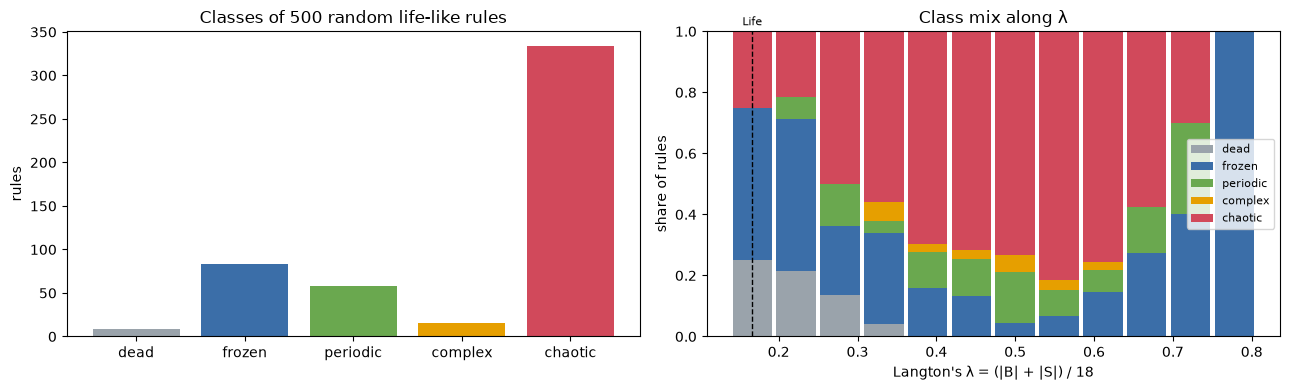

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
counts = [np.sum(classes == c) for c in CLASSES]
left.bar(CLASSES, counts, color=[COLORS[c] for c in CLASSES])
left.set_ylabel("rules")
left.set_title(f"Classes of {N_RULES} random life-like rules")

digits = np.round(lam * 18).astype(int)
levels = np.arange(digits.min(), digits.max() + 1)
bottom = np.zeros(len(levels))
for c in CLASSES:
    share = np.array(
        [np.mean(classes[digits == k] == c) if np.any(digits == k) else 0 for k in levels]
    )
    right.bar(levels / 18, share, bottom=bottom, width=1 / 18 * 0.9, color=COLORS[c], label=c)
    bottom += share
right.axvline(3 / 18, color="black", ls="--", lw=1)
right.text(3 / 18, 1.02, "Life", ha="center", fontsize=8)
right.set_xlabel("Langton's λ = (|B| + |S|) / 18")
right.set_ylabel("share of rules")
right.set_title("Class mix along λ")
right.legend(fontsize=8, loc="center right")
fig.tight_layout()
fig.savefig(FIGURES / "exp04_rulespace.png", dpi=150)
plt.show()

### Birth digits or survival digits?

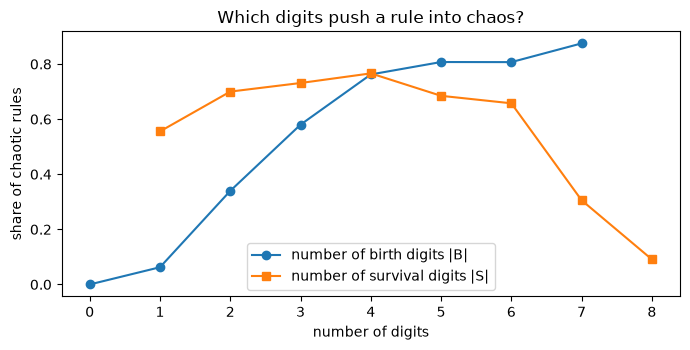

correlation of the number of birth digits with being chaotic: +0.37
correlation of the number of survive digits with being chaotic: -0.21
chaotic rules containing B1: 0.6077844311377245
all rules containing B1:    0.512


In [5]:
n_birth = np.array([len(r.birth) for r in rules])
n_survive = np.array([len(r.survive) for r in rules])

fig, ax = plt.subplots(figsize=(7, 3.6))
for counts, label, marker in [
    (n_birth, "number of birth digits |B|", "o-"),
    (n_survive, "number of survival digits |S|", "s-"),
]:
    ks = np.arange(counts.min(), counts.max() + 1)
    share = [
        np.mean(classes[counts == k] == "chaotic") if np.sum(counts == k) >= 5 else np.nan
        for k in ks
    ]
    ax.plot(ks, share, marker, label=label)
ax.set_xlabel("number of digits")
ax.set_ylabel("share of chaotic rules")
ax.set_title("Which digits push a rule into chaos?")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "exp04_birth_survive.png", dpi=150)
plt.show()

for name, counts in [("birth", n_birth), ("survive", n_survive)]:
    r = np.corrcoef(counts, classes == "chaotic")[0, 1]
    print(f"correlation of the number of {name} digits with being chaotic: {r:+.2f}")
print(
    "chaotic rules containing B1:",
    np.mean([1 in rules[i].birth for i in np.flatnonzero(classes == "chaotic")]),
)
print("all rules containing B1:   ", np.mean([1 in r.birth for r in rules]))

### How much do the conclusions depend on the thresholds?

Both thresholds of `classify_rule` (100 generations for a "long" transient, half of full decorrelation for "chaotic") are halved and increased by half.

In [6]:
print(f"{'long transient':>15} {'chaotic damage':>15}  " + " ".join(f"{c:>9}" for c in CLASSES))
for lt in [50, 100, 150]:
    for cd in [0.25, 0.5, 0.75]:
        alt = np.array([classify_rule(f, long_transient=lt, chaotic_damage=cd) for f in features])
        shares = " ".join(f"{np.mean(alt == c):>9.1%}" for c in CLASSES)
        print(f"{lt:>15} {cd:>15}  {shares}")

 long transient  chaotic damage       dead    frozen  periodic   complex   chaotic
             50            0.25       1.8%     16.0%      8.8%      6.6%     66.8%
             50             0.5       1.8%     16.0%      8.8%      6.6%     66.8%
             50            0.75       1.8%     16.0%      8.8%      6.6%     66.8%
            100            0.25       1.8%     16.6%     11.6%      3.2%     66.8%
            100             0.5       1.8%     16.6%     11.6%      3.2%     66.8%
            100            0.75       1.8%     16.6%     11.6%      3.2%     66.8%
            150            0.25       1.8%     16.6%     12.4%      2.4%     66.8%
            150             0.5       1.8%     16.6%     12.4%      2.4%     66.8%
            150            0.75       1.8%     16.6%     12.4%      2.4%     66.8%


## 4c. Life's neighbourhood

The 17 rules that differ from B3/S23 by adding or removing one digit (B0 excluded), classified with the same settings.

In [7]:
near = neighbours(CONWAY)
near_features = [rule_features(r, seed=1000 + i) for i, r in enumerate(near)]
near_classes = [classify_rule(f) for f in near_features]

print(
    f"{'rule':>16} {'change':>8} {'class':>9} {'settled':>8} {'transient':>10} {'period':>7} "
    f"{'density':>8} {'damage':>7}"
)
for r, f, c in zip(near, near_features, near_classes, strict=True):
    if r.birth != CONWAY.birth:
        k = next(iter(r.birth ^ CONWAY.birth))
        change = f"{'+' if k in r.birth else '-'}B{k}"
    else:
        k = next(iter(r.survive ^ CONWAY.survive))
        change = f"{'+' if k in r.survive else '-'}S{k}"
    print(
        f"{str(r):>16} {change:>8} {c:>9} {f.settled:>8.0%} {f.transient:>10.0f} {f.period:>7.0f} "
        f"{f.density:>8.3f} {f.damage:>7.2f}"
    )
print()
for c in CLASSES:
    print(f"{c:>9}: {near_classes.count(c)} of 17")

with open(DATA / "life_neighbours.csv", "w", encoding="utf-8", newline="\n") as fh:
    fh.write("rule,class," + ",".join(FIELDS) + "\n")
    for r, f, c in zip(near, near_features, near_classes, strict=True):
        fh.write(f"{r},{c}," + ",".join(f"{getattr(f, k):.6g}" for k in FIELDS) + "\n")

            rule   change     class  settled  transient  period  density  damage
         B13/S23      +B1   chaotic       0%        nan     nan    0.376    1.00
         B23/S23      +B2   chaotic       0%        nan     nan    0.390    0.99
           B/S23      -B3    frozen     100%          7       1    0.052    0.05
         B34/S23      +B4   chaotic       0%        nan     nan    0.351    1.00
         B35/S23      +B5   complex     100%        215       2    0.008    1.68
         B36/S23      +B6   complex     100%        437       2    0.017    2.59
         B37/S23      +B7   complex      80%        558       2    0.032    1.19
         B38/S23      +B8   complex     100%        363       1    0.029    1.14
         B3/S023      +S0   chaotic       0%        nan     nan    0.151    1.04
         B3/S123      +S1   chaotic       0%        nan     nan    0.330    1.01
           B3/S3      -S2      dead     100%         10       1    0.000    0.00
           B3/S2      -S3  p

### Check on a larger grid

Classes depend on the grid size through the transient threshold. Life, its complex neighbours and a few reference rules are re-run on a 64 × 64 torus (5 soups each, cap 5000), with the transient threshold scaled up by the same factor that Life's own transient grows.

In [8]:
check = [CONWAY, parse_rule("B2/S"), parse_rule("B3/S012345678")]
check += [r for r, c in zip(near, near_classes, strict=True) if c == "complex"]
life_small = rule_features(CONWAY).transient
life_large = rule_features(CONWAY, size=64, runs=5, max_steps=5000).transient
scale = life_large / life_small
print(
    f"Life's median transient: {life_small:.0f} on 32 × 32, {life_large:.0f} on 64 × 64 "
    f"(threshold scaled by {scale:.1f})"
)
for r in check:
    small = classify_rule(rule_features(r))
    f = rule_features(r, size=64, runs=5, max_steps=5000)
    large = classify_rule(f, long_transient=100 * scale)
    print(
        f"{str(r):>16}: 32 × 32 {small:>9}   64 × 64 {large:>9}   "
        f"(transient {f.transient:.0f}, settled {f.settled:.0%})"
    )

Life's median transient: 431 on 32 × 32, 967 on 64 × 64 (threshold scaled by 2.2)
          B3/S23: 32 × 32   complex   64 × 64   complex   (transient 967, settled 100%)
            B2/S: 32 × 32   chaotic   64 × 64   chaotic   (transient nan, settled 0%)
   B3/S012345678: 32 × 32    frozen   64 × 64    frozen   (transient 7, settled 100%)
         B35/S23: 32 × 32   complex   64 × 64   complex   (transient 307, settled 100%)
         B36/S23: 32 × 32   complex   64 × 64   complex   (transient 597, settled 100%)
         B37/S23: 32 × 32   complex   64 × 64   complex   (transient 1260, settled 80%)
         B38/S23: 32 × 32   complex   64 × 64   complex   (transient 752, settled 100%)
         B3/S237: 32 × 32   complex   64 × 64   chaotic   (transient 2361, settled 20%)
         B3/S238: 32 × 32   complex   64 × 64   complex   (transient 1769, settled 100%)


## Results vs. predictions

| # | Prediction | Result |
|---|---|---|
| 1 | dead or frozen most common | **Wrong:** two thirds of random rules are chaotic (puzzle A). |
| 2 | 5–10 % complex | Slightly high: 3.2 %, or 2.4–6.6 % depending on the threshold. |
| 3 | chaotic rules have high $\lambda$; complex rules cluster at an edge of chaos | First half roughly right (chaos peaks at intermediate-to-high $\lambda$, then falls); second half **not supported**: complex rules do not cluster in $\lambda$ (puzzle D). |
| 4 | about 3 of 17 neighbours still complex | 6 of 17 (5 on the larger grid). |
| 5 | extra survival digits push towards chaos | **Reversed:** extra birth digits, above all B1 and B2, push towards chaos; extra survival digits make chaos less likely (puzzles A and B). |
| 6 | balancing (freezing) loop dominates | **Correct:** B1 wins on every lattice run; reinforcing loops set the transient. |

## Puzzles

The data did a few things that were not obvious in advance. Try each one before opening the answer.

**A. Two thirds of all random rules are chaotic.**
*Hint: what happens if a dead cell with a single live neighbour is born?*

<details><summary>Answer</summary>

With B1 or B2, births happen almost everywhere a live cell is nearby, so any live cell seeds new ones and activity spreads like fire. Half of all rules contain B1 and another quarter contain B2 without B1; 79–83 % of these are chaotic, against 27 % of rules with neither. Life-like rules that are not chaotic almost all start birth at 3 or more neighbours.
</details>

**B. Extra survival digits make chaos less likely, extra birth digits more likely.**
*Hint: what does a survival digit do to a live cell, and what does a birth digit do to an empty one?*

<details><summary>Answer</summary>

Survival digits only keep existing cells alive; they make patterns more persistent, which favours crowded or frozen end states. Birth digits create new cells in empty space, which is what spreads activity (loop R1). Correlations with being chaotic: +0.37 for the number of birth digits, −0.21 for survival digits.
</details>

**C. Adding B5, B6, B7, B8 or S7, S8 to Life changes almost nothing, but adding B1, B2, S0, S1, S5 or S6 tips it into chaos.**
*Hint: how often does a cell in a Life soup actually have 7 live neighbours?*

<details><summary>Answer</summary>

A rule entry only matters if it is used. In Life soups dead cells almost never have 5 or more live neighbours (under 1 % of cell-steps, 0.003 % for 8), so adding B5–B8 hardly ever fires; live cells with 7 or 8 neighbours are similarly rare. Entries that are used often (B1 and B2 about 7 % each, S1 13 %, S5 6 %) change the dynamics completely. B4 (about 1 %) is the exception: each extra birth there feeds more crowded neighbourhoods and the change snowballs.
</details>

**D. Langton's $\lambda$ does not find the complex rules.**
*Hint: $\lambda$ counts how many entries produce life. Does it know which entries are used?*

<details><summary>Answer (partly open)</summary>

$\lambda$ treats B1 and B8 the same, but puzzle C shows that their effects are completely different because B1 is used thousands of times more often. Complex rules in the sample range from $\lambda$ = 0.33 to 0.61, and Life sits at 0.17, outside that range. For life-like rules, a measure weighted by how often each neighbour count occurs would probably be a better coordinate than $\lambda$; that has not been tested here.
</details>

**E. The Replicator rule B1357/S1357 empties a 32 × 32 torus at generation 16, from any starting state, but not a 48 × 48 one.**
*Hint: under this rule a cell's next state is the parity of its live neighbours. What is a parity rule applied 16 times?*

<details><summary>Answer</summary>

For B1357/S1357 the next state of every cell is the parity (odd or even) of its number of live neighbours, whatever the cell's own state, so the update is linear over the integers mod 2: the sum of the eight shifted copies of the grid. Applying it $2^k$ times gives the sum of the eight shifts by $2^k$ cells (all cross terms come in pairs and cancel mod 2). On a 32-cell torus a shift by +16 is the same as a shift by −16, so after 16 steps every shift appears an even number of times and the sum is zero: every grid is empty. On 48 × 48 no such cancellation occurs. Five random soups on 32 × 32 all died at exactly generation 16.
</details>

## Conclusions

- **Feedback loops summarise the first three experiments**: a freezing loop that wins on lattices, reinforcing loops that set how long it takes, a transition when clustering weakens the freezing loop, and a draining loop that keeps driven avalanches from becoming critical.
- **Chaos is the norm in rule space**, driven by low birth digits. Complex behaviour like Life's is rare, about 3 % of rules.
- **Life is moderately robust**: one-digit changes to entries it rarely uses keep it complex; changes to entries it uses often break it. Robustness depends on how a rule is used, not just on how it is written.
- **$\lambda$ is too coarse** to locate complexity among life-like rules.

Limitations and open questions: see the [write-up](../docs/experiments/04-systems.md).